Setup and paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "part_c_text").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

PART_C_DIR = PROJECT_ROOT / "part_c_text"

print("Project root:", PROJECT_ROOT)

Project root: F:\Study\Year_3\Projects\ML\Hushhhhh-machine-is-learning


Load the prepared splits

In [2]:
SPLITS_DIR = PART_C_DIR / "results" / "prepared_data"

def load_prepared_split(name):
    path = SPLITS_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing split file: {path}")
    df = pd.read_csv(path, encoding="utf-8-sig")
    return df[["text", "label"]].dropna().reset_index(drop=True)


train_df = load_prepared_split("train")
val_df = load_prepared_split("validation")
test_df = load_prepared_split("test")
assert (len(train_df), len(val_df), len(test_df)) == (31833, 6821, 6822), "Mismatch with split sizes!#@"

X_train, y_train = train_df["text"].values, train_df["label"].values
X_val, y_val = val_df["text"].values, val_df["label"].values
X_test, y_test = test_df["text"].values, test_df["label"].values

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print("\nTrain class distribution:")
print(train_df["label"].value_counts())

Train: 31833 | Val: 6821 | Test: 6822

Train class distribution:
label
Medical     4550
Tech        4549
Sports      4549
Finance     4549
Politics    4549
Culture     4546
Religion    4541
Name: count, dtype: int64


Build the text pipeline

In [3]:
train_set, val_set, test_set = set(X_train), set(X_val), set(X_test)
assert len(train_set & val_set) == 0, "Data leakage: duplicate texts between train and val!"
assert len(train_set & test_set) == 0, "Data leakage: duplicate texts between train and test!"
assert len(val_set & test_set) == 0, "Data leakage: duplicate texts between val and test!"


def build_text_pipeline(vectorizer_type="tfidf", ngram_range=(1, 1), max_features=20000, classifier=None):
    if vectorizer_type == "bow":
        vectorizer = CountVectorizer(
            ngram_range=ngram_range,
            max_features=max_features,
        )
    elif vectorizer_type == "tfidf":
        vectorizer = TfidfVectorizer(
            ngram_range=ngram_range,
            max_features=max_features,
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
            dtype=np.float32
        )
    else:
        raise ValueError("vectorizer_type must be 'bow' or 'tfidf'")

    if classifier is None:
        classifier = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

    return Pipeline([
        ("vectorizer", vectorizer),
        ("clf", classifier),
    ])

Baseline model

In [4]:
baseline_pipe = build_text_pipeline(
    vectorizer_type="tfidf",
    ngram_range=(1, 1),
    max_features=20000,
    classifier=LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
)

baseline_pipe.fit(X_train, y_train)
baseline_preds = baseline_pipe.predict(X_val)

baseline_acc = accuracy_score(y_val, baseline_preds)
baseline_f1 = f1_score(y_val, baseline_preds, average="macro")
retained_vocab = len(baseline_pipe.named_steps["vectorizer"].vocabulary_)

print(f"Baseline Val Accuracy : {baseline_acc:.4f}")
print(f"Baseline Val Macro F1 : {baseline_f1:.4f}")
print(f"Retained Vocab Size   : {retained_vocab}")

Baseline Val Accuracy : 0.9796
Baseline Val Macro F1 : 0.9796
Retained Vocab Size   : 20000


Compare BoW vs TF-IDF on validation

In [5]:
import time
from sklearn.svm import LinearSVC
from IPython.display import display

vec_configs = [
    {"name": "BoW (1, 1)", "type": "bow", "ngram": (1, 1), "max_feat": 20000},
    {"name": "BoW (1, 2)", "type": "bow", "ngram": (1, 2), "max_feat": 20000},
    {"name": "TF-IDF (1, 1)", "type": "tfidf", "ngram": (1, 1), "max_feat": 20000},
    {"name": "TF-IDF (1, 2)", "type": "tfidf", "ngram": (1, 2), "max_feat": 20000},
]

models_to_test = [
    ("Logistic Regression", lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
    ("LinearSVC", lambda: LinearSVC(C=1.0, max_iter=2000, random_state=RANDOM_STATE)),
]

vec_exp_rows = []
for model_name, model_fn in models_to_test:
    for cfg in vec_configs:
        t0 = time.time()
        pipe = build_text_pipeline(
            vectorizer_type=cfg["type"],
            ngram_range=cfg["ngram"],
            max_features=cfg["max_feat"],
            classifier=model_fn(),
        )
        pipe.fit(X_train, y_train)
        elapsed = time.time() - t0

        preds = pipe.predict(X_val)
        vec_exp_rows.append({
            "Model": model_name,
            "Representation": cfg["name"],
            "vec_type": cfg["type"],
            "ngram": cfg["ngram"],
            "max_feat": cfg["max_feat"],
            "Val Accuracy": round(accuracy_score(y_val, preds), 4),
            "Val Macro F1": round(f1_score(y_val, preds, average="macro"), 4),
            "Time (s)": round(elapsed, 2),
        })

vec_comparison_df = pd.DataFrame(vec_exp_rows)
display(vec_comparison_df[["Model", "Representation", "Val Accuracy", "Val Macro F1", "Time (s)"]])

# pick best vectorizer independently for each model
lr_subset = vec_comparison_df[vec_comparison_df["Model"] == "Logistic Regression"]
best_lr_vec = lr_subset.loc[lr_subset["Val Macro F1"].idxmax()]

svc_subset = vec_comparison_df[vec_comparison_df["Model"] == "LinearSVC"]
best_svc_vec = svc_subset.loc[svc_subset["Val Macro F1"].idxmax()]

print(f"Best Vectorizer for Logistic Regression : {best_lr_vec['Representation']} (F1 = {best_lr_vec['Val Macro F1']})")
print(f"Best Vectorizer for LinearSVC           : {best_svc_vec['Representation']} (F1 = {best_svc_vec['Val Macro F1']})")

,Model,Representation,Val Accuracy,Val Macro F1,Time (s)
0,Logistic Regression,"BoW (1, 1)",0.9767,0.9767,7.38
1,Logistic Regression,"BoW (1, 2)",0.9777,0.9777,31.29
2,Logistic Regression,"TF-IDF (1, 1)",0.9796,0.9796,8.57
3,Logistic Regression,"TF-IDF (1, 2)",0.9799,0.9799,31.69
4,LinearSVC,"BoW (1, 1)",0.9742,0.9742,19.05
5,LinearSVC,"BoW (1, 2)",0.9760,0.9759,44.18
6,LinearSVC,"TF-IDF (1, 1)",0.9827,0.9827,8.51
7,LinearSVC,"TF-IDF (1, 2)",0.9834,0.9834,30.95


Best Vectorizer for Logistic Regression : TF-IDF (1, 2) (F1 = 0.9799)
Best Vectorizer for LinearSVC           : TF-IDF (1, 2) (F1 = 0.9834)


Tune the regularisation strength C

In [6]:
tuning_rows = []

best_lr_pipeline, best_lr_f1, best_lr_acc, best_lr_time, best_lr_c = None, -1.0, -1.0, float("inf"), None
for c in [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    t0 = time.time()
    pipe = build_text_pipeline(
        vectorizer_type=best_lr_vec["vec_type"],
        ngram_range=best_lr_vec["ngram"],
        max_features=int(best_lr_vec["max_feat"]),
        classifier=LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE),
    )
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    preds = pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1 = f1_score(y_val, preds, average="macro")
    tuning_rows.append({
        "Model": "Logistic Regression",
        "Vectorizer": best_lr_vec["Representation"],
        "C": c,
        "Val Accuracy": round(acc, 4),
        "Val Macro F1": round(f1, 4),
        "Time (s)": round(elapsed, 2),
    })
    if (f1, acc) > (best_lr_f1, best_lr_acc):
        best_lr_f1, best_lr_acc, best_lr_time = f1, acc, elapsed
        best_lr_pipeline, best_lr_c = pipe, c

best_svc_pipeline, best_svc_f1, best_svc_acc, best_svc_time, best_svc_c = None, -1.0, -1.0, float("inf"), None
for c in [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    t0 = time.time()
    pipe = build_text_pipeline(
        vectorizer_type=best_svc_vec["vec_type"],
        ngram_range=best_svc_vec["ngram"],
        max_features=int(best_svc_vec["max_feat"]),
        classifier=LinearSVC(C=c, max_iter=2000, random_state=RANDOM_STATE),
    )
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    preds = pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1 = f1_score(y_val, preds, average="macro")
    tuning_rows.append({
        "Model": "LinearSVC",
        "Vectorizer": best_svc_vec["Representation"],
        "C": c,
        "Val Accuracy": round(acc, 4),
        "Val Macro F1": round(f1, 4),
        "Time (s)": round(elapsed, 2),
    })
    if (f1, acc) > (best_svc_f1, best_svc_acc):
        best_svc_f1, best_svc_acc, best_svc_time = f1, acc, elapsed
        best_svc_pipeline, best_svc_c = pipe, c

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

lr_label = f"Logistic Regression ({best_lr_vec['Representation']}, C={best_lr_c})"
svc_label = f"LinearSVC ({best_svc_vec['Representation']}, C={best_svc_c})"

val_summary_df = pd.DataFrame([
    {"Model": lr_label, "Val Accuracy": round(best_lr_acc, 4), "Val Macro F1": round(best_lr_f1, 4), "Train Time (s)": round(best_lr_time, 2)},
    {"Model": svc_label, "Val Accuracy": round(best_svc_acc, 4), "Val Macro F1": round(best_svc_f1, 4), "Train Time (s)": round(best_svc_time, 2)},
])
display(val_summary_df)

if (best_svc_f1, best_svc_acc) >= (best_lr_f1, best_lr_acc):
    winner_key = "svc"
    overall_best_pipeline = best_svc_pipeline
    overall_best_name = svc_label
else:
    winner_key = "lr"
    overall_best_pipeline = best_lr_pipeline
    overall_best_name = lr_label

print("Selected champion model:", overall_best_name)

,Model,Vectorizer,C,Val Accuracy,Val Macro F1,Time (s)
0,Logistic Regression,"TF-IDF (1, 2)",0.05,0.9654,0.9654,29.86
1,Logistic Regression,"TF-IDF (1, 2)",0.10,0.9714,0.9714,29.63
2,Logistic Regression,"TF-IDF (1, 2)",0.50,0.9773,0.9773,28.80
3,Logistic Regression,"TF-IDF (1, 2)",1.00,0.9799,0.9799,29.90
4,Logistic Regression,"TF-IDF (1, 2)",2.00,0.9809,0.9809,30.05
5,Logistic Regression,"TF-IDF (1, 2)",5.00,0.9817,0.9817,31.08
6,LinearSVC,"TF-IDF (1, 2)",0.01,0.9720,0.9720,31.70
7,LinearSVC,"TF-IDF (1, 2)",0.05,0.9782,0.9781,31.09
8,LinearSVC,"TF-IDF (1, 2)",0.10,0.9793,0.9793,30.91
9,LinearSVC,"TF-IDF (1, 2)",0.50,0.9830,0.9830,31.60


,Model,Val Accuracy,Val Macro F1,Train Time (s)
0,"Logistic Regression (TF-IDF (1, 2), C=5.0)",0.9817,0.9817,31.08
1,"LinearSVC (TF-IDF (1, 2), C=5.0)",0.9836,0.9836,31.96


Selected champion model: LinearSVC (TF-IDF (1, 2), C=5.0)


Final evaluation on the test set

,Model,Test Accuracy,Test Macro F1,Test Weighted F1
0,"Logistic Regression (TF-IDF (1, 2), C=5.0)",0.9811,0.9811,0.9811
1,"LinearSVC (TF-IDF (1, 2), C=5.0) [Champion]",0.9815,0.9815,0.9815



Classification Report — Logistic Regression (TF-IDF (1, 2), C=5.0):
              precision    recall  f1-score   support

     Culture     0.9754    0.9764    0.9759       975
     Finance     0.9806    0.9856    0.9831       974
     Medical     0.9766    0.9856    0.9811       975
    Politics     0.9815    0.9805    0.9810       975
    Religion     0.9722    0.9692    0.9707       973
      Sports     0.9959    0.9949    0.9954       975
        Tech     0.9855    0.9754    0.9804       975

    accuracy                         0.9811      6822
   macro avg     0.9811    0.9811    0.9811      6822
weighted avg     0.9811    0.9811    0.9811      6822


Classification Report — LinearSVC (TF-IDF (1, 2), C=5.0):
              precision    recall  f1-score   support

     Culture     0.9725    0.9785    0.9755       975
     Finance     0.9786    0.9846    0.9816       974
     Medical     0.9826    0.9867    0.9846       975
    Politics     0.9826    0.9836    0.9831       975
    

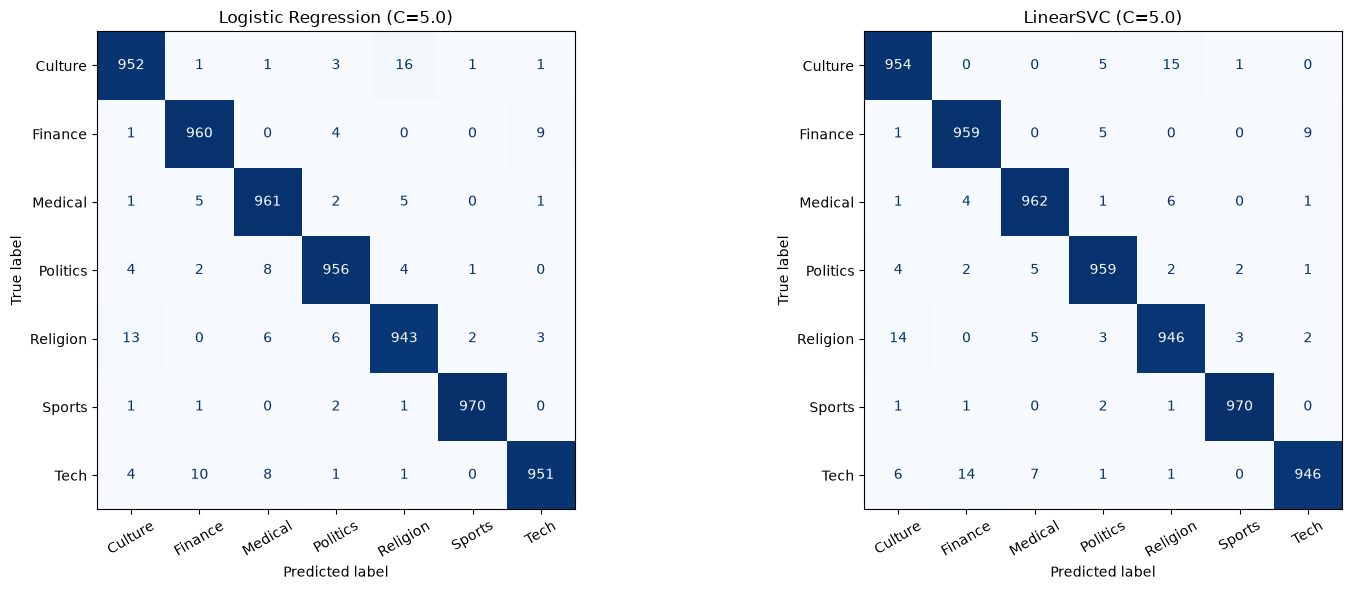

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

lr_test_preds = best_lr_pipeline.predict(X_test)
svc_test_preds = best_svc_pipeline.predict(X_test)

champion_test_preds = svc_test_preds if winner_key == "svc" else lr_test_preds

final_test_df = pd.DataFrame([
    {
        "Model": f"{lr_label} [Champion]" if winner_key == "lr" else lr_label,
        "Test Accuracy": round(accuracy_score(y_test, lr_test_preds), 4),
        "Test Macro F1": round(f1_score(y_test, lr_test_preds, average="macro"), 4),
        "Test Weighted F1": round(f1_score(y_test, lr_test_preds, average="weighted"), 4),
    },
    {
        "Model": f"{svc_label} [Champion]" if winner_key == "svc" else svc_label,
        "Test Accuracy": round(accuracy_score(y_test, svc_test_preds), 4),
        "Test Macro F1": round(f1_score(y_test, svc_test_preds, average="macro"), 4),
        "Test Weighted F1": round(f1_score(y_test, svc_test_preds, average="weighted"), 4),
    },
])
display(final_test_df)

print(f"\nClassification Report — {lr_label}:")
print(classification_report(y_test, lr_test_preds, digits=4))

print(f"\nClassification Report — {svc_label}:")
print(classification_report(y_test, svc_test_preds, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_preds = [
    (lr_test_preds, f"Logistic Regression (C={best_lr_c})"),
    (svc_test_preds, f"LinearSVC (C={best_svc_c})"),
]

for ax, (preds, title) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, preds, labels=overall_best_pipeline.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=overall_best_pipeline.classes_)
    disp.plot(cmap="Blues", ax=ax, values_format="d", xticks_rotation=30, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
figures_dir = PART_C_DIR / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "part_c_confusion_matrix.png", dpi=300)
plt.show()

Error analysis

In [8]:
errors_df = pd.DataFrame({
    "text": X_test,
    "true": y_test,
    "pred": champion_test_preds,
})
misclassified = errors_df[errors_df["true"] != errors_df["pred"]].copy()

print(f"Total misclassified: {len(misclassified)} / {len(X_test)} ({len(misclassified) / len(X_test):.2%})")

print("\nErrors per true class:")
print(misclassified["true"].value_counts())

print("\nTop confused class pairs (True -> Predicted):")
pair_counts = misclassified.groupby(["true", "pred"]).size().sort_values(ascending=False)
print(pair_counts.head(5))

top_true, top_pred = pair_counts.index[0]
print(f"\nSample articles for top confusion ({top_true} -> {top_pred}):")
sample_errors = misclassified[(misclassified["true"] == top_true) & (misclassified["pred"] == top_pred)]
for _, row in sample_errors.head(3).iterrows():
    print("-" * 50)
    print(row["text"][:220] + "...")

Total misclassified: 126 / 6822 (1.85%)

Errors per true class:
true
Tech        29
Religion    27
Culture     21
Politics    16
Finance     15
Medical     13
Sports       5
Name: count, dtype: int64

Top confused class pairs (True -> Predicted):
true      pred    
Culture   Religion    15
Tech      Finance     14
Religion  Culture     14
Finance   Tech         9
Tech      Medical      7
dtype: int64

Sample articles for top confusion (Culture -> Religion):
--------------------------------------------------
يستذكر الفنان ناصر نصر الله رمضان ثلاث محطات مهمة الاولي فترة الطفولة منطقة الغبيبة الشارقة واتسمت الفترة ببداية الاكتشاف الطفولي لرمضان يمثله اجواء احتفالية خصوصا صلاة التراويح الاطفال يحرصون حضورها والتمتع باجوائها الر...
--------------------------------------------------
يدهشك الكاتب والقاص عبدالرضا السجواني يتناول ذكرياته القديمة فهي الاكثر حميمية اني نقلها اليك ولعل الحديث ياخذ بعدا مؤثرا ذكرياته الرمضانية تعود ايام الطفولة والصبا المرحلة تدل انجازاته الكتابية براعته وصفها يقول

Export the test results

In [9]:
classes = [str(c) for c in overall_best_pipeline.classes_]
misclassified_rate = len(misclassified) / len(X_test)

report_lines = [
    "Part C - Test Set Results",
    "=" * 50,
    f"Champion Model: {overall_best_name}",
    "Test Metrics:",
    final_test_df.to_string(index=False),
]

for label, preds in [(lr_label, lr_test_preds), (svc_label, svc_test_preds)]:
    cm = confusion_matrix(y_test, preds, labels=overall_best_pipeline.classes_)
    cm_df = pd.DataFrame(cm, index=classes, columns=classes)

    report_lines.extend([
        f"\nClassification Report - {label}:",
        classification_report(y_test, preds, digits=4),
        f"Confusion Matrix (Rows=True, Cols=Pred) - {label}:",
        cm_df.to_string(),
    ])

report_lines.extend([
    f"\nError Analysis ({overall_best_name}):",
    f"Total misclassified: {len(misclassified)} / {len(X_test)} ({misclassified_rate:.2%})",
    "\nErrors per true class:",
    misclassified["true"].value_counts().to_string(),
    "\nTop confused pairs (True -> Predicted):",
    pair_counts.head(5).to_string(),
])

report_dir = PART_C_DIR / "report"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = report_dir / "test_results.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
final_test_df.to_csv(report_dir / "test_metrics.csv", index=False)

print(f"Saved test results to: {report_path}")

Saved test results to: F:\Study\Year_3\Projects\ML\Hushhhhh-machine-is-learning\part_c_text\report\test_results.txt


Save the champion model

In [10]:
import joblib

models_dir = PROJECT_ROOT / "models" / "text"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "arabic_news_pipeline.pkl"

joblib.dump(overall_best_pipeline, model_path)
print(f"Saved champion model ({overall_best_name}) to: {model_path}")

reloaded_pipe = joblib.load(model_path)
sample_text = X_test[0]
print("Reload check:", reloaded_pipe.predict([sample_text])[0], "| expected:", y_test[0])

Saved champion model (LinearSVC (TF-IDF (1, 2), C=5.0)) to: F:\Study\Year_3\Projects\ML\Hushhhhh-machine-is-learning\models\text\arabic_news_pipeline.pkl
Reload check: Sports | expected: Sports
